
# Gradient Boosting

Gradient Boosting is an ensemble machine learning algorithm that combines multiple weak learners, typically decision trees, to create a strong predictive model.

It builds models sequentially, where each new model attempts to correct the errors made by the previous models. Unlike Random Forest, which builds decision trees independently, Gradient Boosting trains each tree based on the shortcomings of the existing ensemble.

The algorithm uses gradient descent to minimize a specified loss function by identifying the direction in which prediction errors can be reduced.

Each new tree contributes to the overall prediction, with its contribution controlled by a learning rate.

### Key Characteristics

- **Ensemble Learning:** Combines multiple weak learners to improve predictive performance.
- **Sequential Training:** Models are built one after another.
- **Error Correction:** Each subsequent learner focuses on reducing the errors of the existing ensemble.
- **Gradient Descent:** Uses gradients of a loss function to guide model optimization.
- **Learning Rate:** Controls the contribution of each new learner.
- **Versatility:** Supports both regression and classification tasks.

### Types of Gradient Boosting

1. **Gradient Boosting Regressor:** Used to predict continuous numerical values.
2. **Gradient Boosting Classifier:** Used to predict categorical class labels.

### Applications

- House price prediction
- Fraud detection
- Credit risk assessment
- Customer churn prediction
- Medical diagnosis
- Sales forecasting

### Advantages

- Can capture complex nonlinear relationships.
- Combines multiple weak learners to improve predictive performance.
- Supports different loss functions.
- Provides feature importance scores.

### Limitations

- Sequential training can be computationally expensive.
- Can overfit if not properly regularized.
- Sensitive to hyperparameter choices.
- Requires careful tuning of learning rate and number of estimators.

In [2]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing, load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import GradientBoostingRegressor, GradientBoostingClassifier
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix,roc_auc_score,roc_curve)

## Regression

In [1]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.datasets import load_diabetes

SEED = 23

X, y = load_diabetes(return_X_y=True)

train_X, test_X, train_y, test_y = train_test_split(X, y, 
                                                    test_size = 0.25, 
                                                    random_state = SEED)

gbr = GradientBoostingRegressor(loss='absolute_error',learning_rate=0.1,n_estimators=300,max_depth = 1, random_state = SEED,max_features = 5)

gbr.fit(train_X, train_y)

pred_y = gbr.predict(test_X)

test_rmse = mean_squared_error(test_y, pred_y) ** (1 / 2)

print('Root mean Square error: {:.2f}'.format(test_rmse))

Root mean Square error: 56.39


In [3]:
# load dataset
housing = fetch_california_housing()
# Convert features into a DataFrame
housing_df = pd.DataFrame(housing.data, columns=housing.feature_names)

# Add target variable
housing_df['MedHouseVal'] = housing.target

print(housing_df.shape)
housing_df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [5]:
# Column names
print("\nColumns:")
print(housing_df.columns.tolist())

# Dataset information
print("\nDataset Information:")
housing_df.info()

# Statistical summary
print("\nStatistical Summary:")
housing_df.describe()


Columns:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Statistical Summary:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


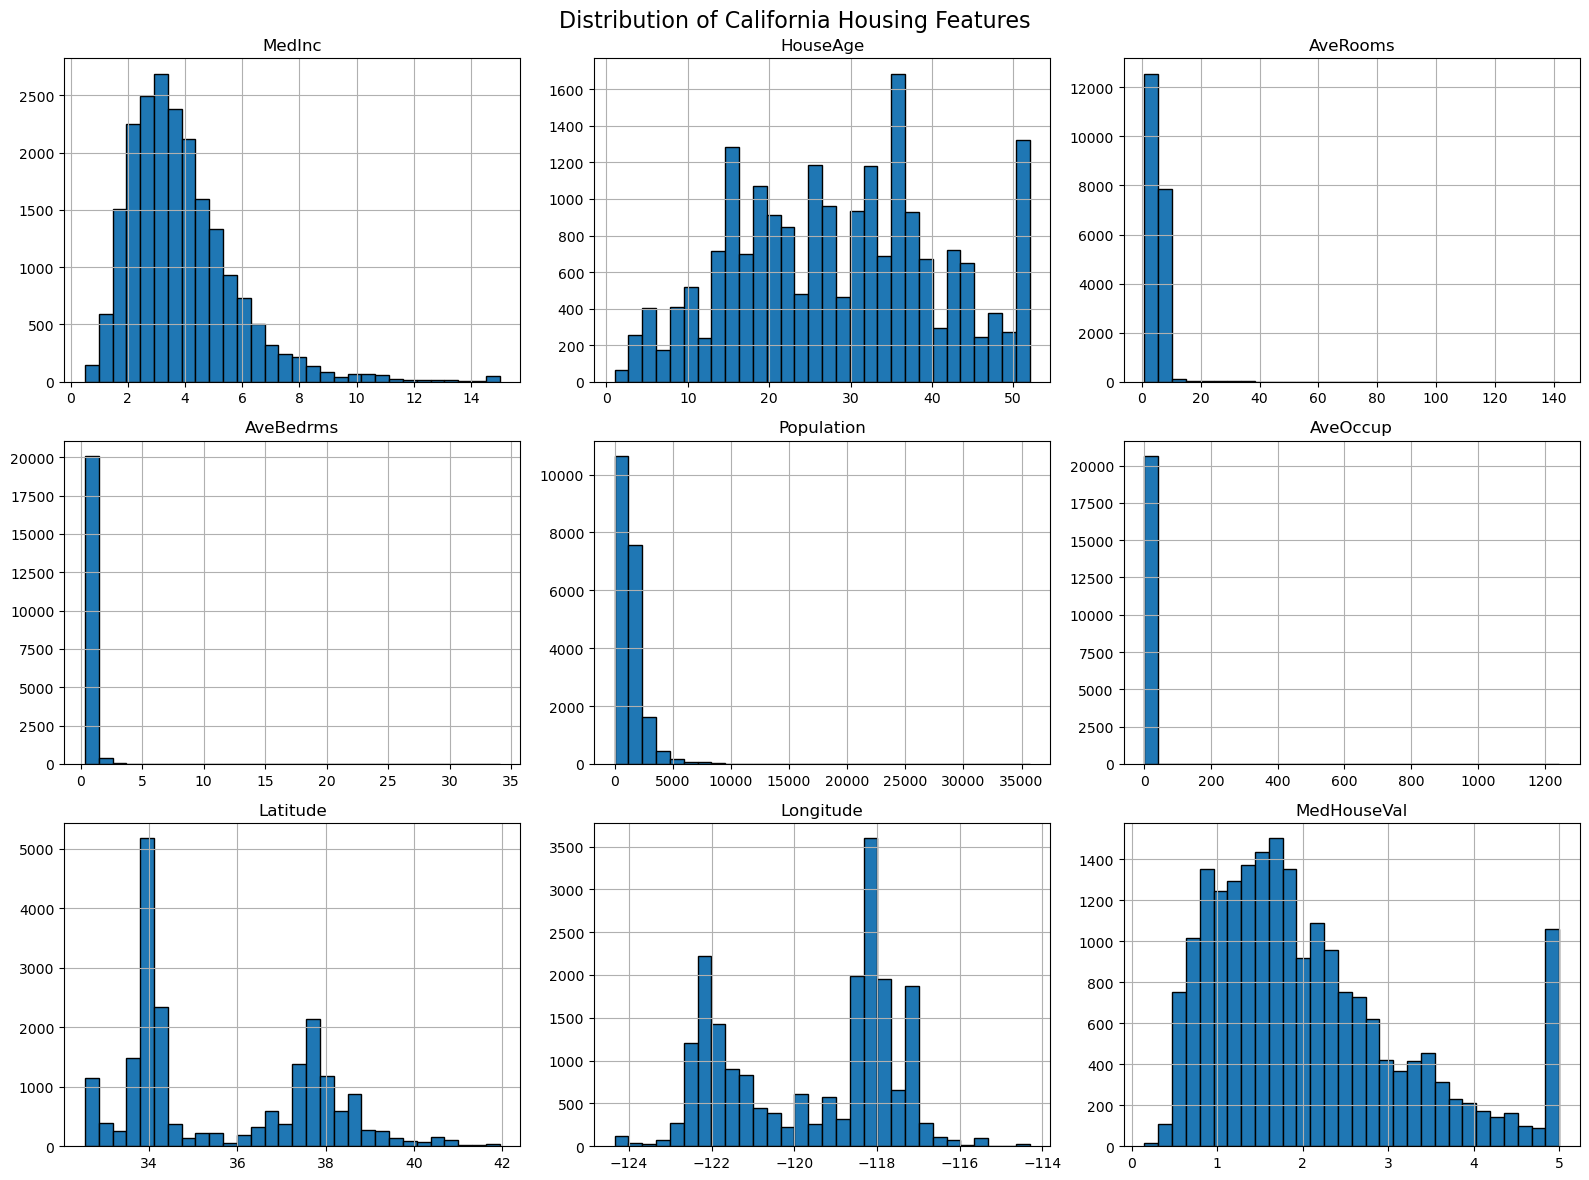

In [7]:
# numerical features distribution
housing_df.hist(figsize=(16, 12), bins=30, edgecolor='black')

plt.suptitle('Distribution of California Housing Features', fontsize=16)
plt.tight_layout()
plt.show()

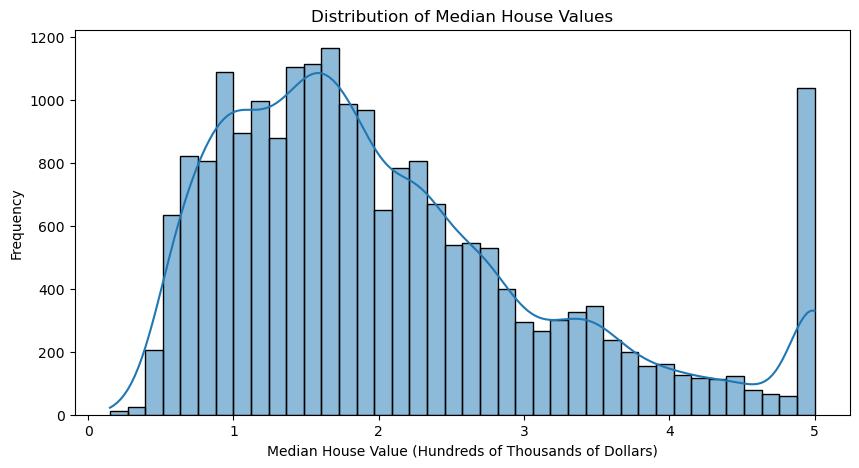

In [9]:
# target disribution

plt.figure(figsize=(10, 5))

sns.histplot(housing_df['MedHouseVal'], bins=40, kde=True)

plt.title('Distribution of Median House Values')
plt.xlabel('Median House Value (Hundreds of Thousands of Dollars)')
plt.ylabel('Frequency')

plt.show()

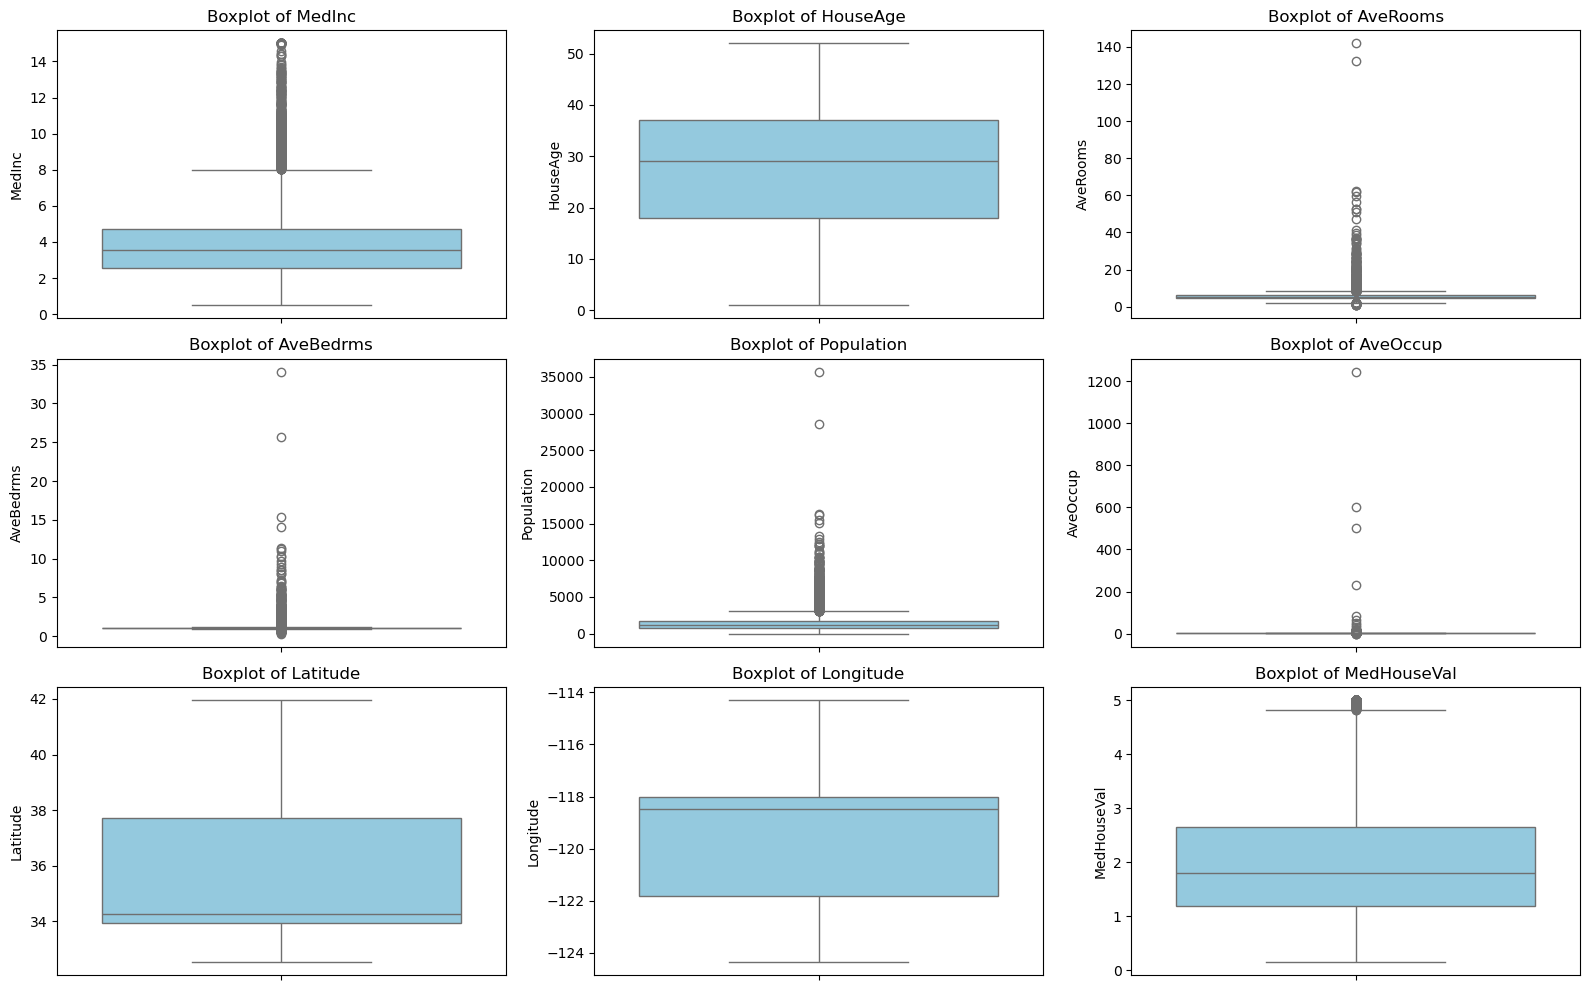

In [12]:
# outlier detection

plt.figure(figsize=(16, 10))

for i, column in enumerate(housing_df.columns, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=housing_df[column], color='skyblue')
    plt.title(f'Boxplot of {column}')

plt.tight_layout()
plt.show()

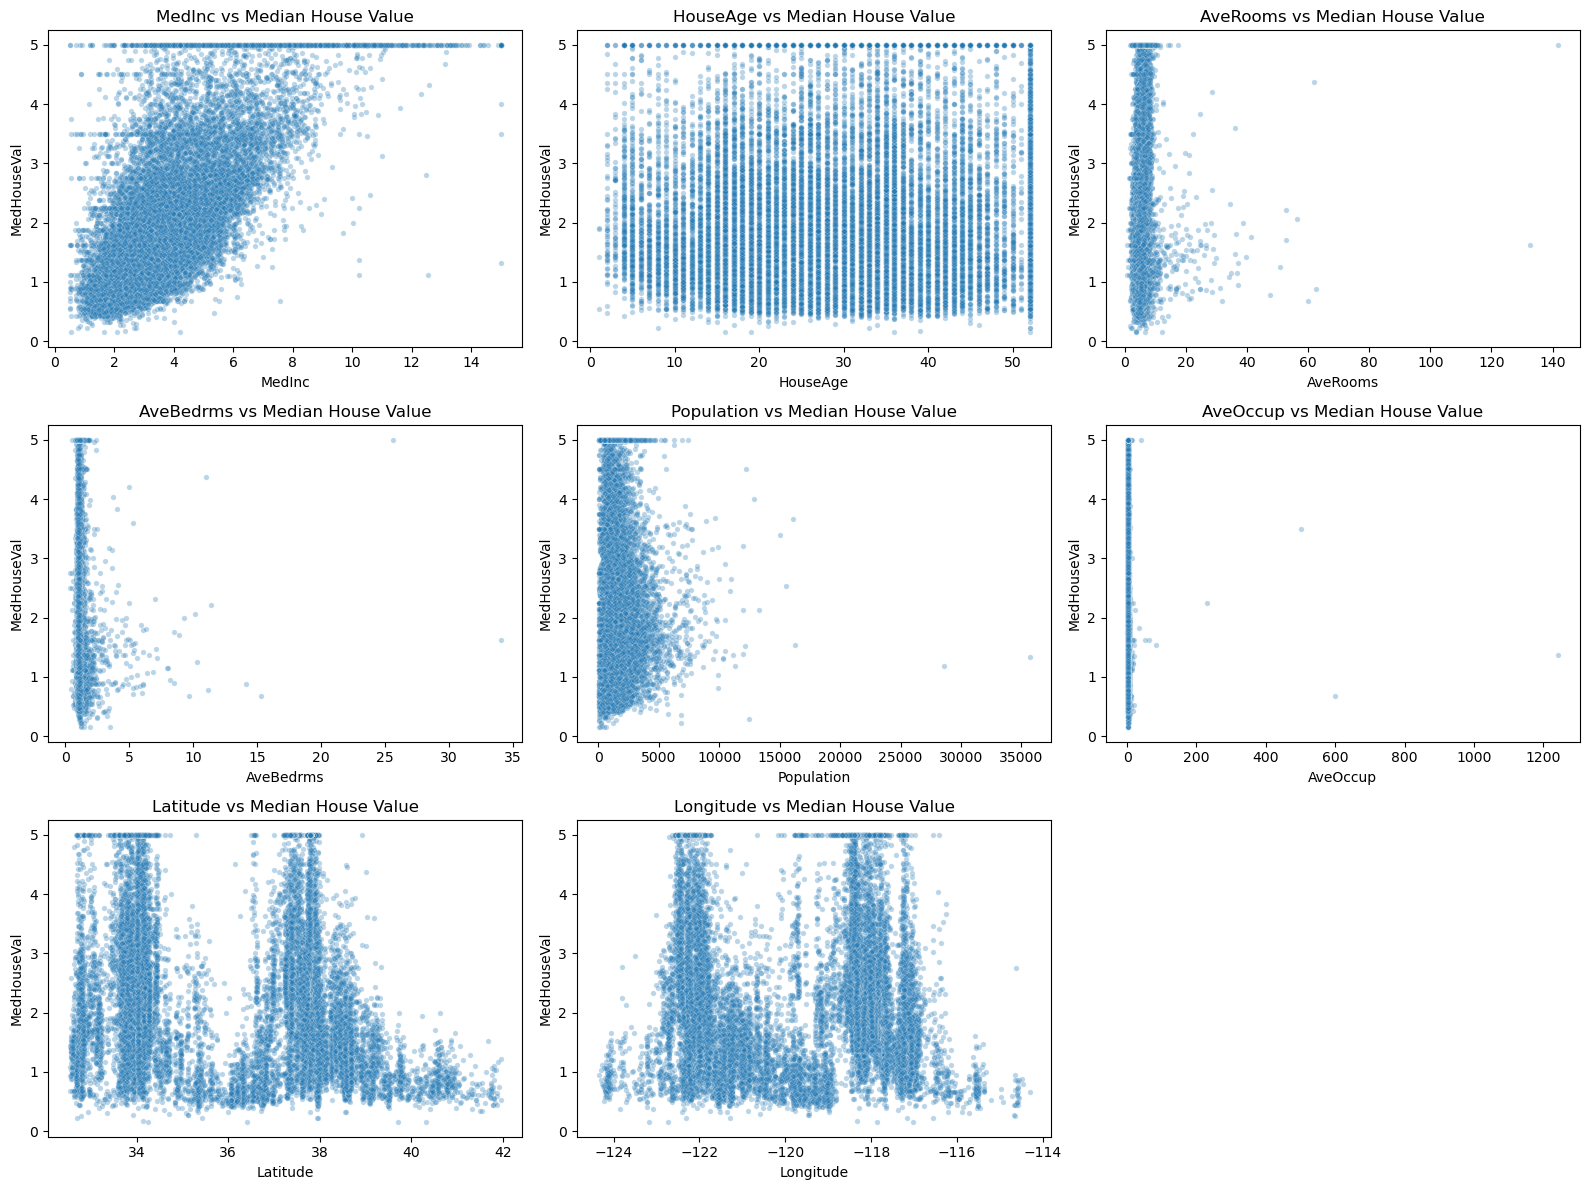

In [15]:
# feature rlships with target

features = [
    'MedInc',
    'HouseAge',
    'AveRooms',
    'AveBedrms',
    'Population',
    'AveOccup',
    'Latitude',
    'Longitude'
]

plt.figure(figsize=(16, 12))

for i, feature in enumerate(features, 1):
    plt.subplot(3, 3, i)
    
    sns.scatterplot(data=housing_df,x=feature,y='MedHouseVal',alpha=0.3,s=15)
    
    plt.title(f'{feature} vs Median House Value')

plt.tight_layout()
plt.show()

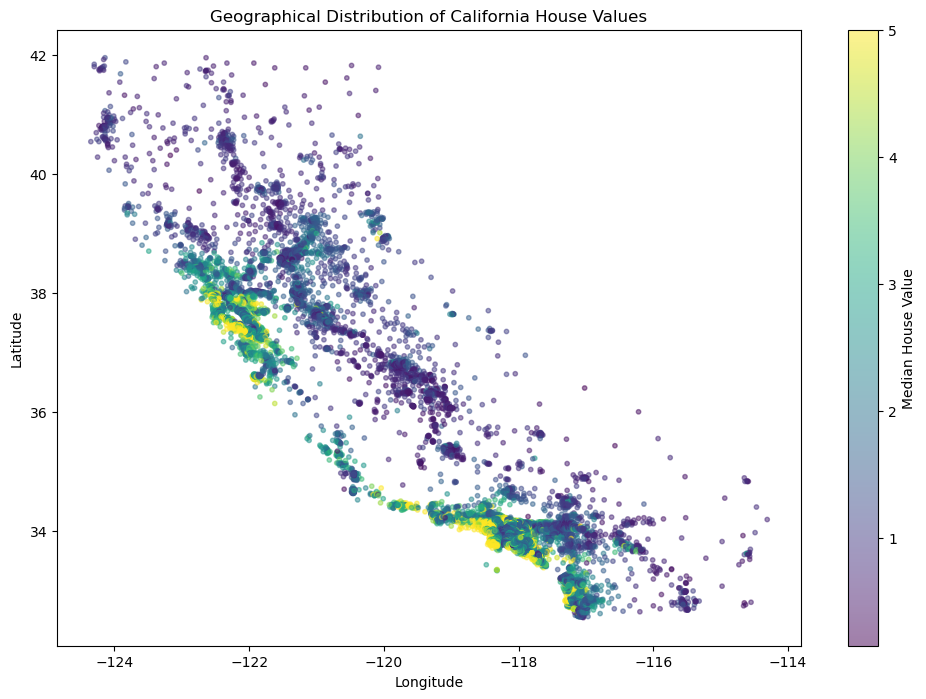

In [18]:
# Geographical distribution of house values

plt.figure(figsize=(12, 8))

scatter = plt.scatter(housing_df['Longitude'],housing_df['Latitude'],c=housing_df['MedHouseVal'],cmap='viridis',alpha=0.5,s=10)

plt.colorbar(scatter, label='Median House Value')

plt.title('Geographical Distribution of California House Values')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

plt.show()

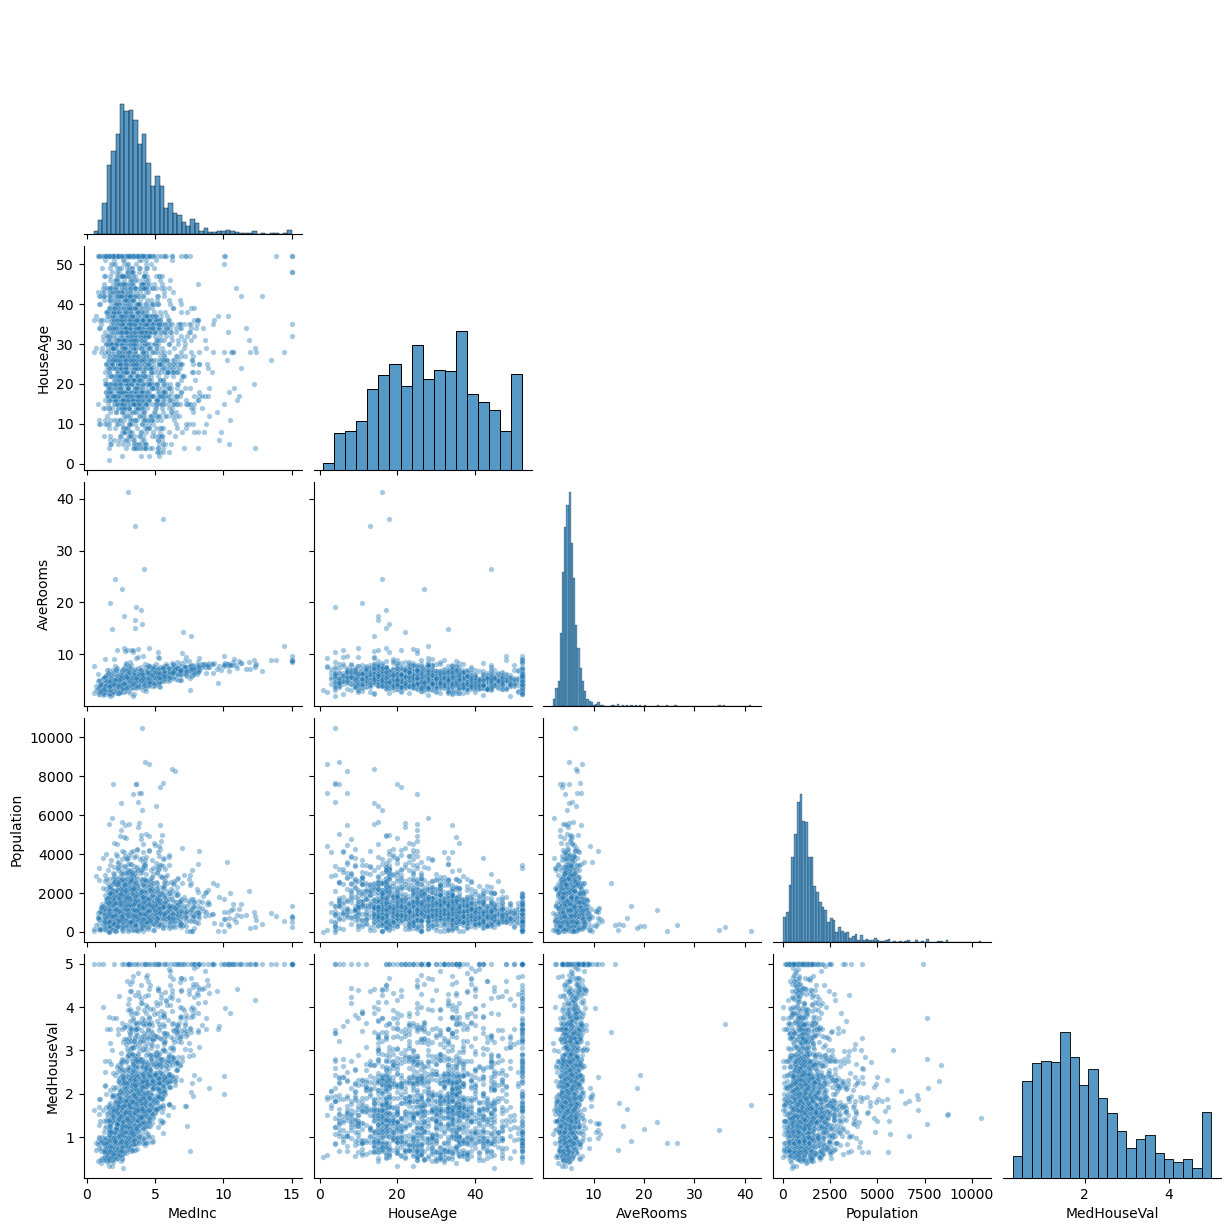

In [20]:
# selected features

sample_df = housing_df.sample(n=2000, random_state=42)

sns.pairplot(
    sample_df[
        ['MedInc', 'HouseAge', 'AveRooms', 'Population', 'MedHouseVal']
    ],
    diag_kind='hist',
    corner=True,
    plot_kws={'alpha': 0.4, 's': 15}
)

plt.show()

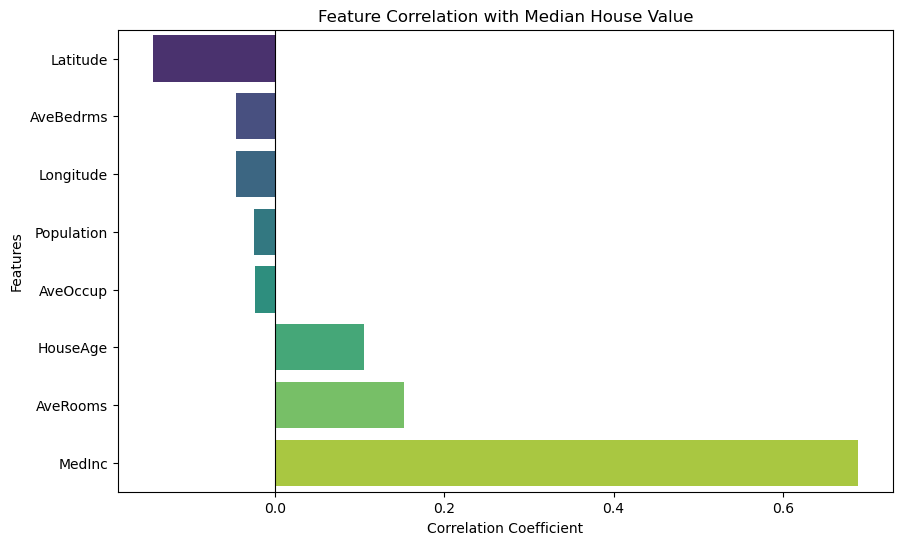

In [14]:
# feature correlation with target

target_corr = housing_df.corr()['MedHouseVal'].drop('MedHouseVal')

target_corr = target_corr.sort_values()

plt.figure(figsize=(10, 6))

sns.barplot(x=target_corr.values,y=target_corr.index,hue=target_corr.index,palette='viridis',legend=False)

plt.title('Feature Correlation with Median House Value')
plt.xlabel('Correlation Coefficient')
plt.ylabel('Features')
plt.axvline(0, color='black', linewidth=0.8)

plt.show()

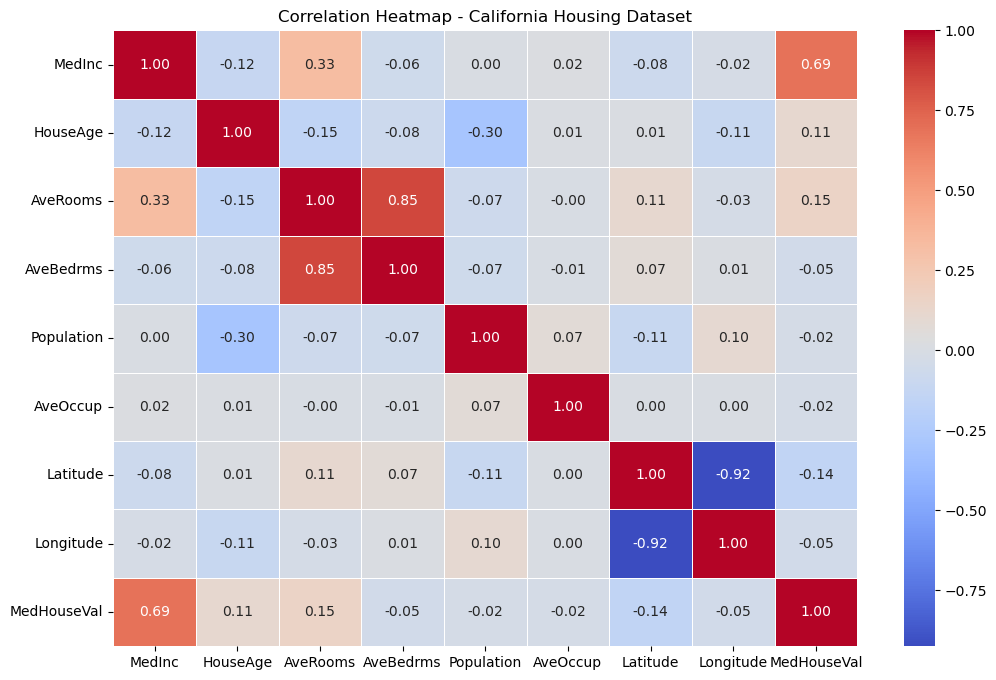

In [21]:
# Correlaion analysis
# correlation matrix
correlation_matrix = housing_df.corr()

# correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(correlation_matrix,annot=True,cmap='coolwarm',fmt='.2f',linewidths=0.5)

plt.title('Correlation Heatmap - California Housing Dataset')
plt.show()

In [23]:
# Preprocessing

# independent variables
X = housing_df.drop('MedHouseVal', axis=1)

# dependent variable
y = housing_df['MedHouseVal']

# Display feature and target dimensions
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)


Features Shape: (20640, 8)
Target Shape: (20640,)


In [24]:

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

# dataset dimensions
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Features: (16512, 8)
Testing Features: (4128, 8)
Training Target: (16512,)
Testing Target: (4128,)


In [25]:
# Modelling

# Initialize Gradient Boosting Regressor
gbr = GradientBoostingRegressor(random_state=42)

# Train the model
gbr.fit(X_train, y_train)

,loss,'squared_error'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [26]:
# predictions
y_pred = gbr.predict(X_test)

# Display actual and predicted values
gbr_results = pd.DataFrame({
    'Actual Values': y_test.values,
    'Predicted Values': y_pred
})

display(gbr_results.head(10))

,Actual Values,Predicted Values
0,0.47700,0.505188
1,0.45800,1.093346
2,5.00001,4.245710
3,2.18600,2.545174
4,2.78000,2.279103
5,1.58700,1.723910
6,1.98200,2.337197
7,1.57500,1.719774
8,3.40000,3.099624
9,4.46600,4.304469


In [27]:
# Evaluation
gbr_mae = mean_absolute_error(y_test, y_pred)
gbr_mse = mean_squared_error(y_test, y_pred)
gbr_rmse = np.sqrt(gbr_mse)
gbr_r2 = r2_score(y_test, y_pred)

# Display results
print(f"MAE:  {gbr_mae:.6f}")
print(f"MSE:  {gbr_mse:.6f}")
print(f"RMSE: {gbr_rmse:.6f}")
print(f"R2 Score: {gbr_r2:.6f}")

MAE:  0.371643
MSE:  0.293997
RMSE: 0.542215
R2 Score: 0.775645


In [28]:
# training vs testing performance

# Generate training predictions
y_train_pred = gbr.predict(X_train)

# Calculate R2 scores
train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_pred)

print(f"Training R2 Score: {train_r2:.6f}")
print(f"Testing R2 Score: {test_r2:.6f}")

Training R2 Score: 0.804898
Testing R2 Score: 0.775645


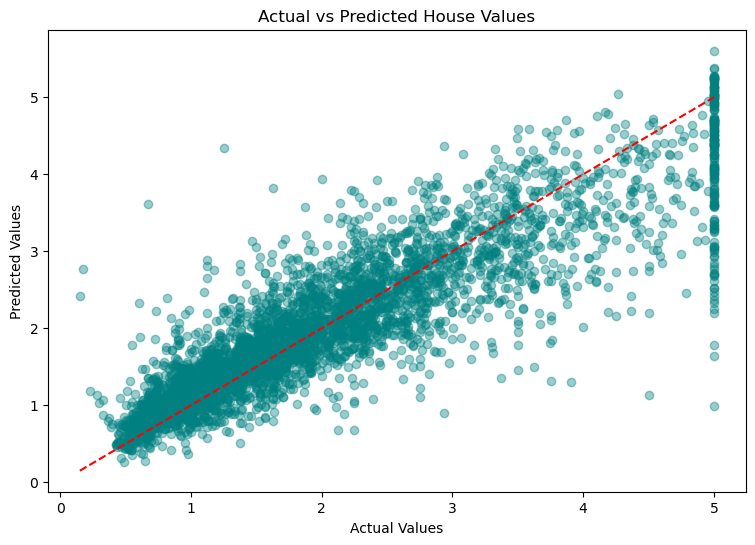

In [29]:
# Actual vs predicted
plt.figure(figsize=(9, 6))

plt.scatter(y_test, y_pred, alpha=0.4, color='teal')

# Perfect prediction reference line
plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()],color='red',linestyle='--')

plt.title('Actual vs Predicted House Values')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')

plt.show()

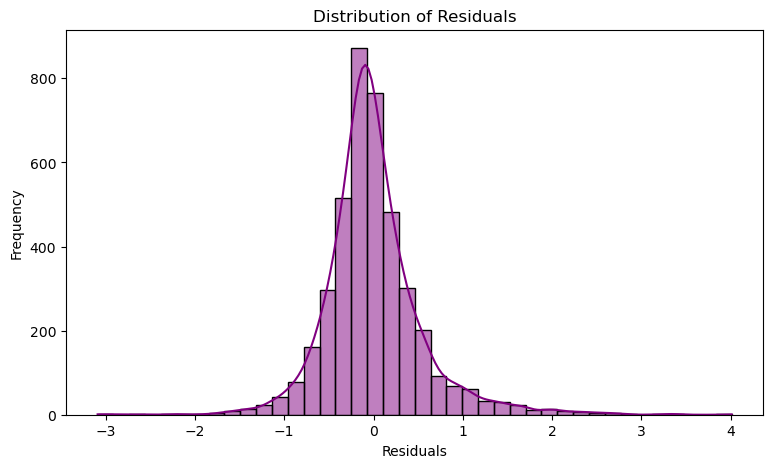

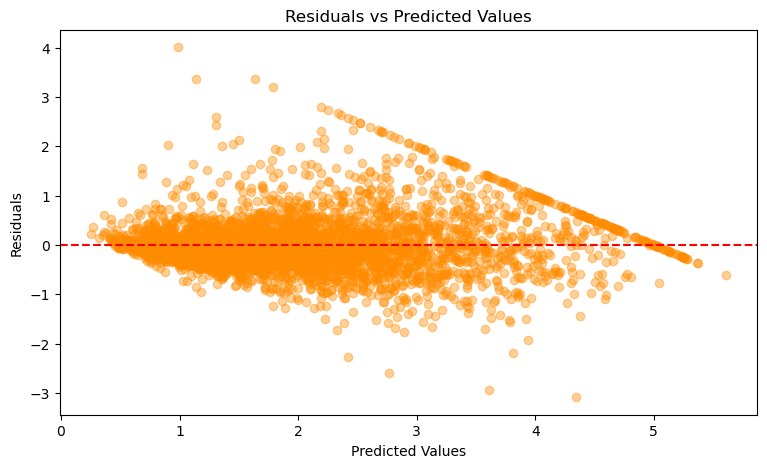

In [30]:
# Residual analysis

# Calculate residuals
residuals = y_test - y_pred

# Residual distribution
plt.figure(figsize=(9, 5))

sns.histplot(residuals, bins=40, kde=True, color='purple')

plt.title('Distribution of Residuals')
plt.xlabel('Residuals')
plt.ylabel('Frequency')

plt.show()

# Residuals vs predicted values
plt.figure(figsize=(9, 5))

plt.scatter(y_pred, residuals, alpha=0.4, color='darkorange')
plt.axhline(y=0, color='red', linestyle='--')

plt.title('Residuals vs Predicted Values')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')

plt.show()

,Feature,Importance
0,MedInc,0.604259
5,AveOccup,0.122835
7,Longitude,0.109853
6,Latitude,0.098533
1,HouseAge,0.034113
2,AveRooms,0.023948
3,AveBedrms,0.005106
4,Population,0.001354


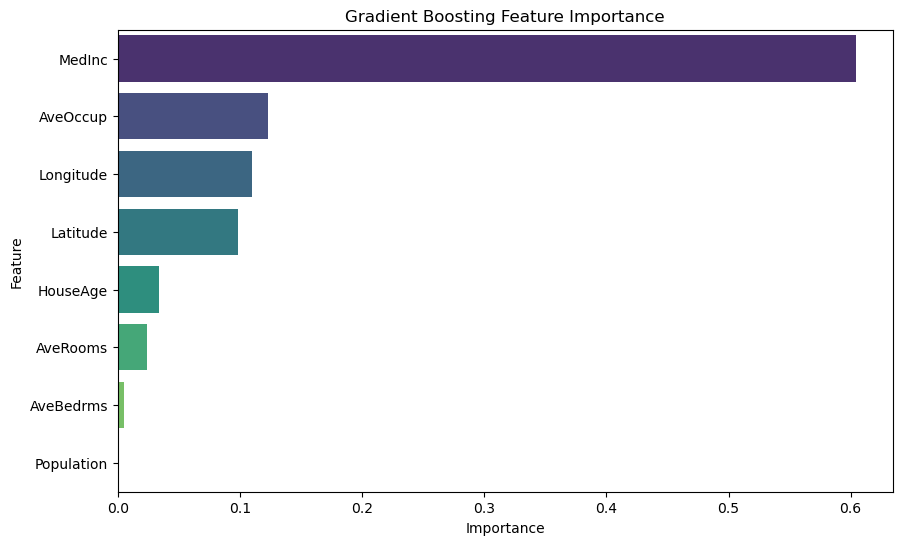

In [31]:
# feature importance

# Extract feature importance
gbr_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': gbr.feature_importances_
})

# Sort feature importance
gbr_importance = gbr_importance.sort_values(by='Importance',ascending=False)

display(gbr_importance)

# Visualize feature importance
plt.figure(figsize=(10, 6))

sns.barplot(data=gbr_importance,x='Importance',y='Feature',hue='Feature',palette='viridis',legend=False)

plt.title('Gradient Boosting Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')

plt.show()

In [33]:
# Hyperparameter Tuning

# Define hyperparameter grid
param_grid = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.05, 0.1],
    'max_depth': [2, 3],
    'min_samples_split': [2, 5],
    'subsample': [0.8, 1.0]
}

# Initialize GridSearchCV
gbr_grid = GridSearchCV(estimator=GradientBoostingRegressor(random_state=42),param_grid=param_grid,cv=3,scoring='neg_mean_squared_error',n_jobs=-1,verbose=1)

# Fit GridSearchCV
gbr_grid.fit(X_train, y_train)

Fitting 3 folds for each of 48 candidates, totalling 144 fits


,estimator,GradientBoost...ndom_state=42)
,param_grid,"{'learning_rate': [0.05, 0.1], 'max_depth': [2, 3], 'min_samples_split': [2, 5], 'n_estimators': [50, 100, ...], ...}"
,scoring,'neg_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,3
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,loss,'squared_error'


In [34]:
# Best hyperparameters
print("Best Parameters:")
print(gbr_grid.best_params_)

# Best cross-validation score
print("\nBest CV RMSE:", np.sqrt(-gbr_grid.best_score_))

Best Parameters:
{'learning_rate': 0.1, 'max_depth': 3, 'min_samples_split': 5, 'n_estimators': 150, 'subsample': 1.0}

Best CV RMSE: 0.5181841757817482


In [35]:

# Retrieve best model
gbr_tuned = gbr_grid.best_estimator_

# Generate predictions
y_pred_tuned = gbr_tuned.predict(X_test)

In [36]:

# Calculate tuned model metrics
tuned_mae = mean_absolute_error(y_test, y_pred_tuned)
tuned_mse = mean_squared_error(y_test, y_pred_tuned)
tuned_rmse = np.sqrt(tuned_mse)
tuned_r2 = r2_score(y_test, y_pred_tuned)

print(f"MAE:  {tuned_mae:.6f}")
print(f"MSE:  {tuned_mse:.6f}")
print(f"RMSE: {tuned_rmse:.6f}")
print(f"R2 Score: {tuned_r2:.6f}")

MAE:  0.357501
MSE:  0.273434
RMSE: 0.522909
R2 Score: 0.791337


In [37]:
# Compare model performance
gbr_comparison = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2 Score'],
    'Original Model': [gbr_mae, gbr_mse, gbr_rmse, gbr_r2],
    'Tuned Model': [tuned_mae, tuned_mse, tuned_rmse, tuned_r2]
})

display(gbr_comparison)

,Metric,Original Model,Tuned Model
0,MAE,0.371643,0.357501
1,MSE,0.293997,0.273434
2,RMSE,0.542215,0.522909
3,R2 Score,0.775645,0.791337


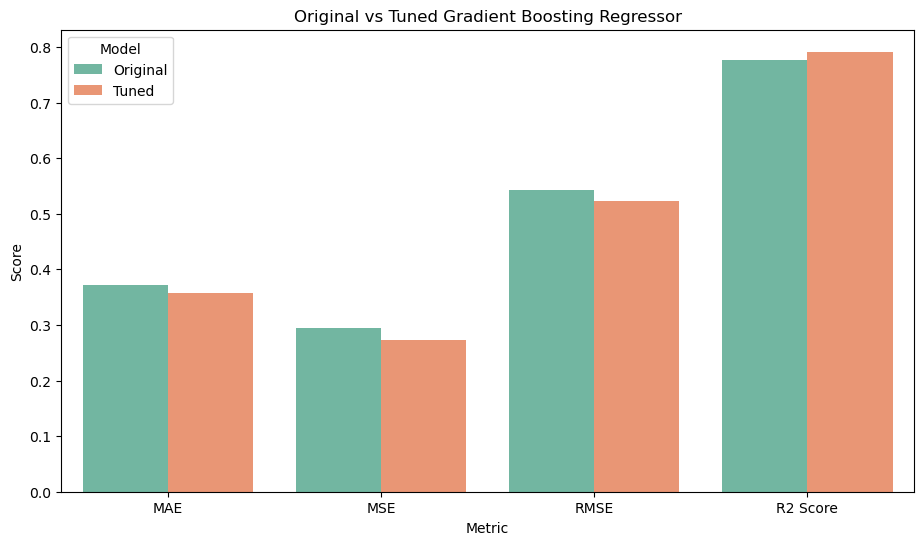

In [38]:
# Plot original vs tuned model performance
metrics = ['MAE', 'MSE', 'RMSE', 'R2 Score']

original_scores = [gbr_mae, gbr_mse, gbr_rmse, gbr_r2]
tuned_scores = [tuned_mae, tuned_mse, tuned_rmse, tuned_r2]

comparison_plot = pd.DataFrame({
    'Metric': metrics * 2,
    'Score': original_scores + tuned_scores,
    'Model': ['Original'] * 4 + ['Tuned'] * 4
})

plt.figure(figsize=(11, 6))

sns.barplot(data=comparison_plot,x='Metric',y='Score',hue='Model',palette='Set2')

plt.title('Original vs Tuned Gradient Boosting Regressor')
plt.show()

### Conclusion

The Gradient Boosting Regressor was implemented using the California Housing dataset to predict median house values.

The baseline model achieved an R² score of 0.775645, indicating that it explained approximately 77.56% of the variation in the target variable.

Hyperparameter tuning using GridSearchCV improved the model's performance across all four evaluation metrics.

The tuned model achieved:
- MAE: 0.357501
- MSE: 0.273434
- RMSE: 0.522909
- R² Score: 0.791337

The improvement demonstrates the importance of hyperparameter optimization in developing effective ensemble models.

Overall, Gradient Boosting provided good predictive performance by sequentially combining decision trees to reduce prediction errors.


## Classification

In [39]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.datasets import load_digits

SEED = 23

X, y = load_digits(return_X_y=True)

train_X, test_X, train_y, test_y = train_test_split(X, y, 
                                                    test_size = 0.25, 
                                                    random_state = SEED)

gbc = GradientBoostingClassifier(n_estimators=300,
                                 learning_rate=0.05,
                                 random_state=100,
                                 max_features=5 )
                                 
gbc.fit(train_X, train_y)

pred_y = gbc.predict(test_X)

acc = accuracy_score(test_y, pred_y)
print("Gradient Boosting Classifier accuracy is : {:.2f}".format(acc))

Gradient Boosting Classifier accuracy is : 0.98


### Breast cancer

In [40]:
# Load Breast Cancer dataset
cancer = load_breast_cancer()

# Convert features into a DataFrame
cancer_df = pd.DataFrame(cancer.data,columns=cancer.feature_names)

# Add target variable
cancer_df['target'] = cancer.target

print(cancer_df.shape)
cancer_df.head()

(569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [41]:
# Column names
print("\nColumns:")
print(cancer_df.columns.tolist())

# Dataset information
print("\nDataset Information:")
cancer_df.info()

# Statistical summary
print("\nStatistical Summary:")
display(cancer_df.describe())

# Missing values
print("\nMissing Values:")
print(cancer_df.isnull().sum().sum())

# Duplicate records
print("\nDuplicate Rows:", cancer_df.duplicated().sum())



Columns:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'target']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   me

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000



Missing Values:
0

Duplicate Rows: 0


target
1    357
0    212
Name: count, dtype: int64


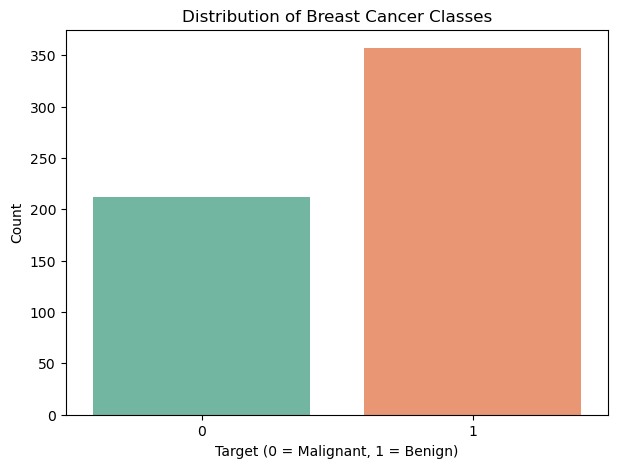

In [42]:
# Target class distribution
print(cancer_df['target'].value_counts())

# Visualize class distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=cancer_df,x='target',hue='target',palette='Set2',legend=False)

plt.title('Distribution of Breast Cancer Classes')
plt.xlabel('Target (0 = Malignant, 1 = Benign)')
plt.ylabel('Count')

plt.show()

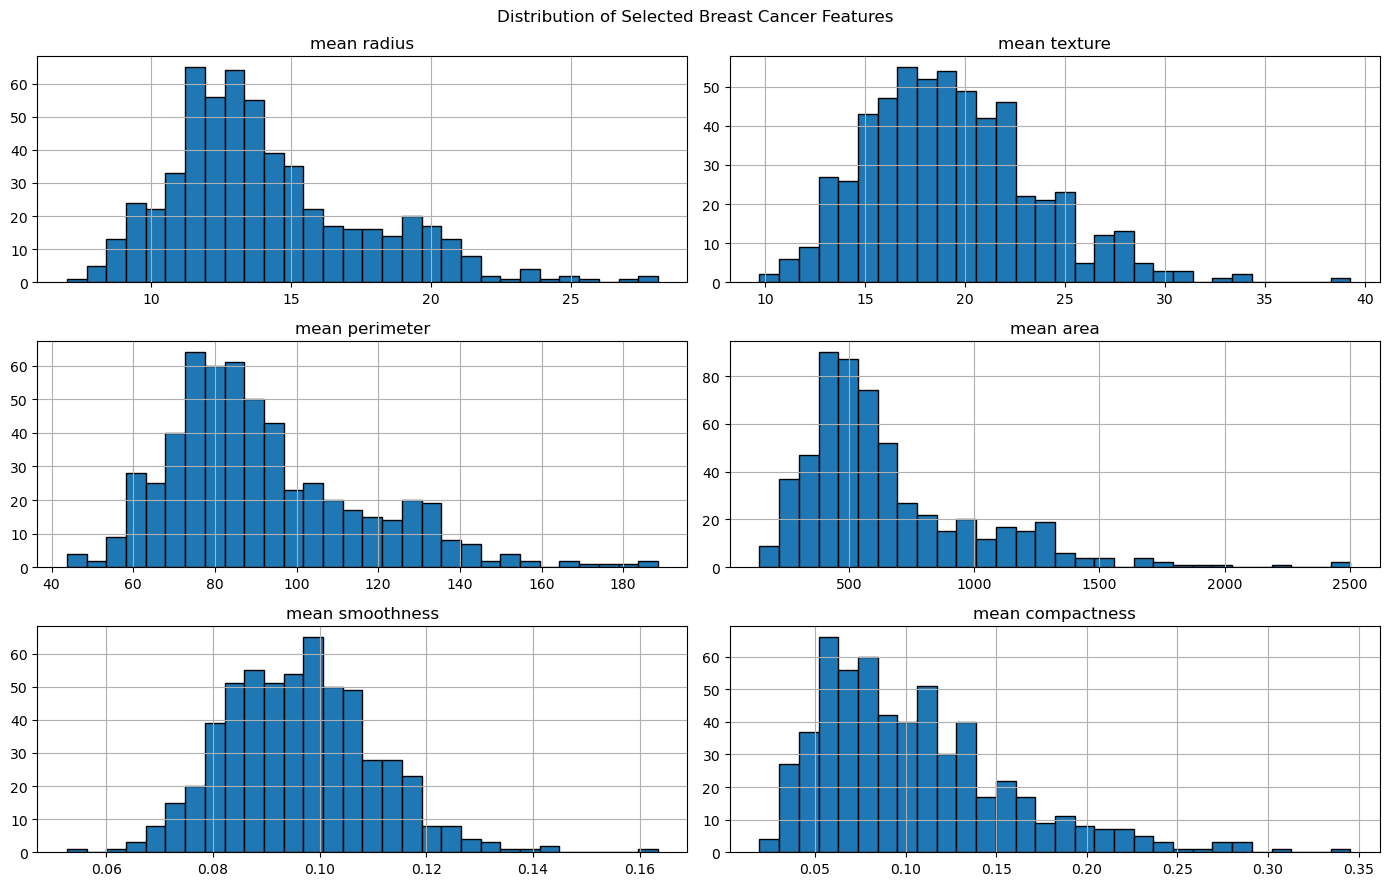

In [43]:
# numerical features distribution
# Select a sample of features for visualization
selected_features = [
    'mean radius',
    'mean texture',
    'mean perimeter',
    'mean area',
    'mean smoothness',
    'mean compactness'
]

cancer_df[selected_features].hist(figsize=(14, 9),bins=30,edgecolor='black')

plt.suptitle('Distribution of Selected Breast Cancer Features')
plt.tight_layout()
plt.show()

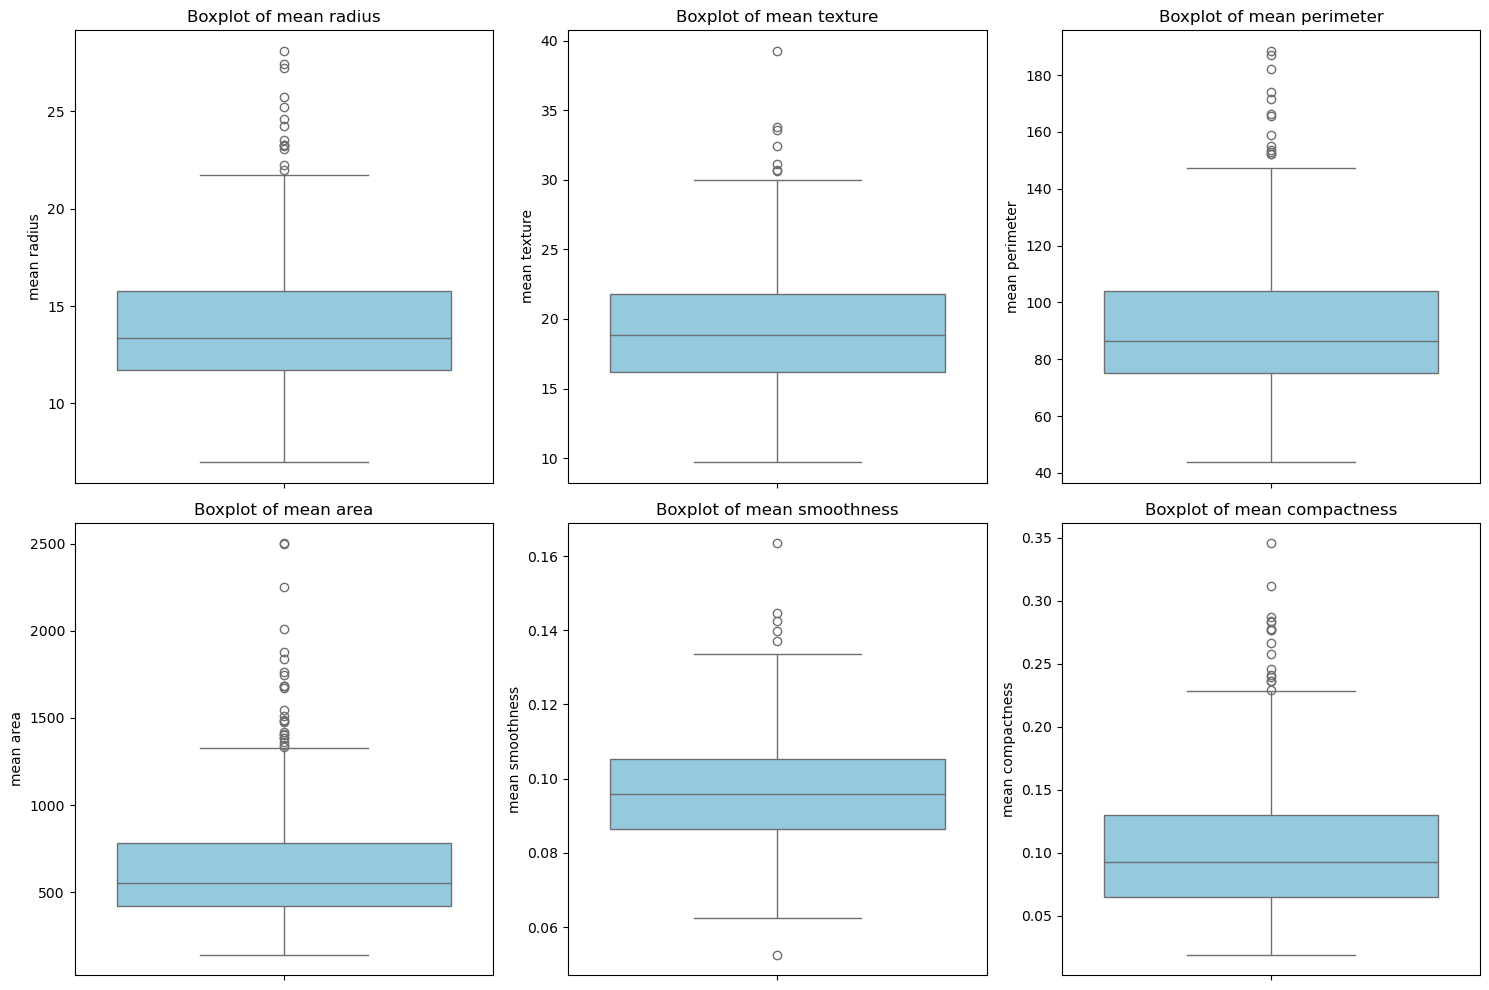

In [44]:
# outlier detection
plt.figure(figsize=(15, 10))
for i, column in enumerate(selected_features, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=cancer_df[column], color='skyblue')
    plt.title(f'Boxplot of {column}')

plt.tight_layout()
plt.show()

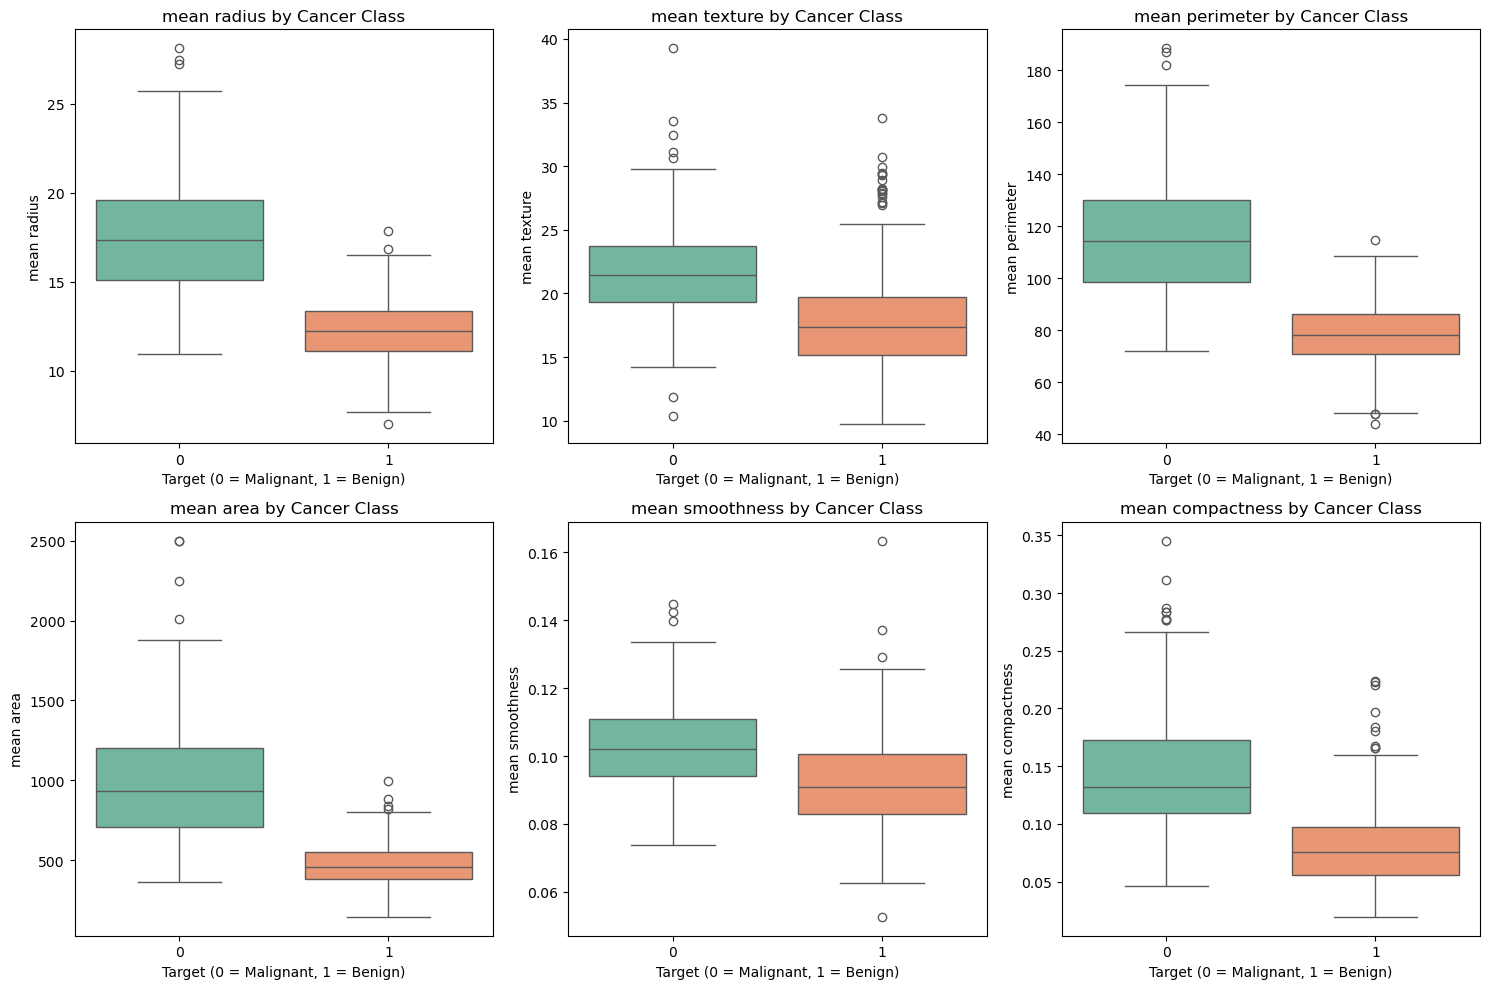

In [45]:
# Visualize selected feature relationships
plt.figure(figsize=(15, 10))

for i, feature in enumerate(selected_features, 1):
    plt.subplot(2, 3, i)

    sns.boxplot(data=cancer_df,x='target',y=feature,hue='target',palette='Set2',legend=False)

    plt.title(f'{feature} by Cancer Class')
    plt.xlabel('Target (0 = Malignant, 1 = Benign)')

plt.tight_layout()
plt.show()

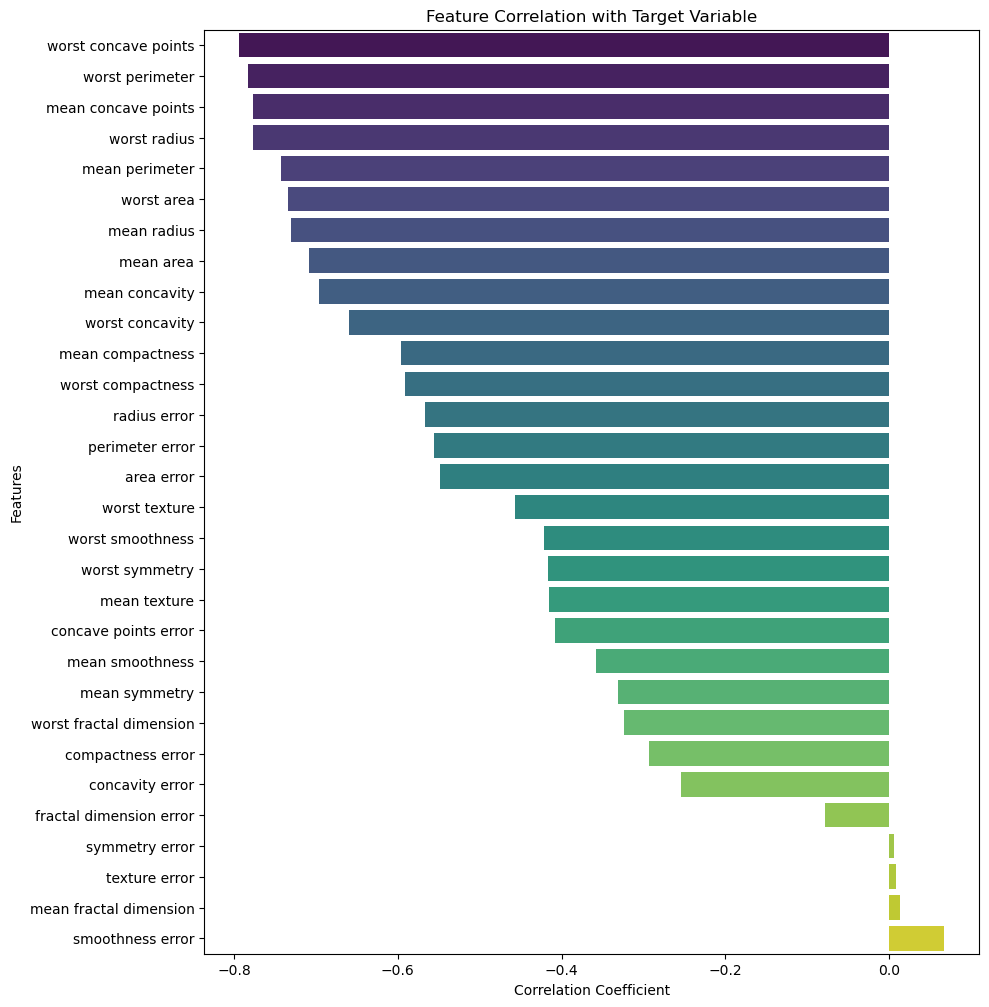

In [46]:
# feature correlation with target
target_corr = cancer_df.corr()['target'].drop('target')

target_corr = target_corr.sort_values()

plt.figure(figsize=(10, 12))

sns.barplot(x=target_corr.values,y=target_corr.index,hue=target_corr.index,palette='viridis',legend=False)

plt.title('Feature Correlation with Target Variable')
plt.xlabel('Correlation Coefficient')
plt.ylabel('Features')

plt.show()

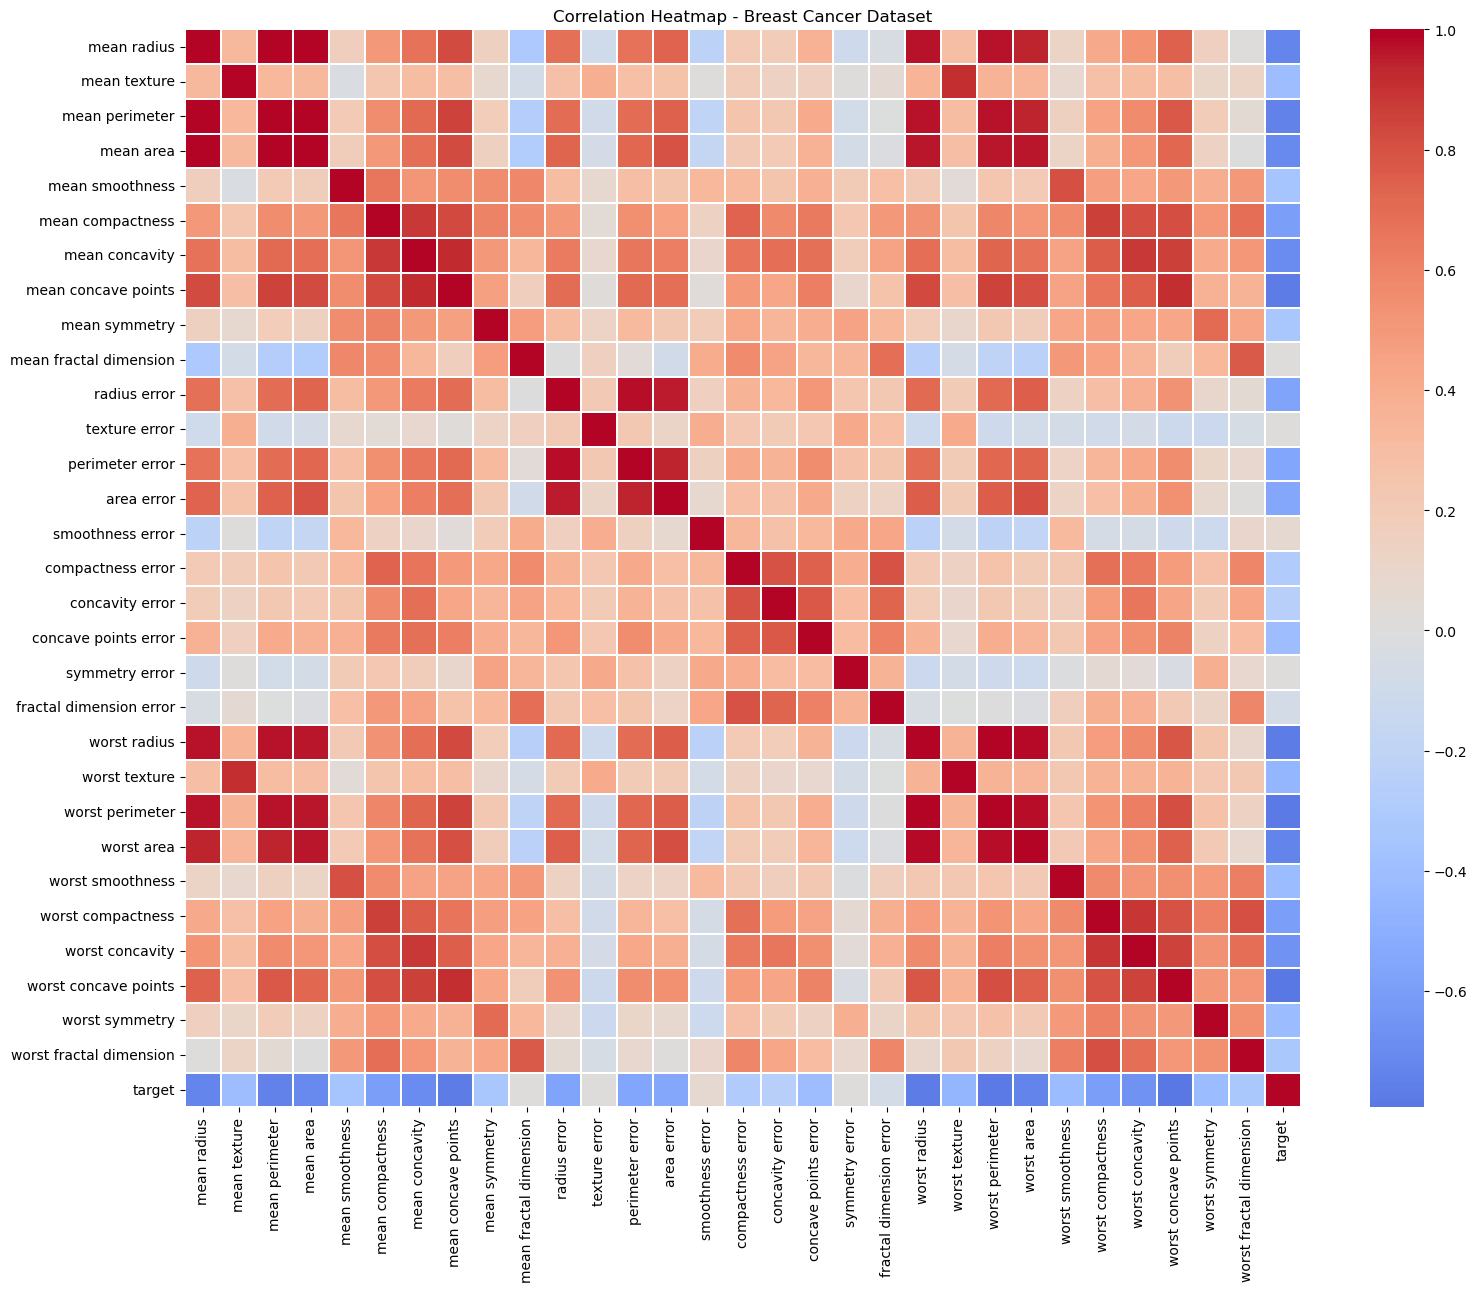

In [48]:
# Correlation analysis
# Calculate correlation matrix
cancer_corr = cancer_df.corr()

# Correlation heatmap
plt.figure(figsize=(18, 14))

sns.heatmap(cancer_corr,cmap='coolwarm',center=0,linewidths=0.2)

plt.title('Correlation Heatmap - Breast Cancer Dataset')
plt.show()

In [49]:
# Preprocessing
# Define independent variables
X = cancer_df.drop('target', axis=1)

# Define dependent variable
y = cancer_df['target']

# Display dimensions
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (569, 30)
Target Shape: (569,)


In [50]:
# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

# Display dimensions
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (455, 30)
Testing Features: (114, 30)
Training Target: (455,)
Testing Target: (114,)


In [51]:
# Check training class distribution
print("Training Class Distribution:")
print(y_train.value_counts())

print("\nTraining Class Proportions:")
print(y_train.value_counts(normalize=True))

# Check testing class distribution
print("\nTesting Class Distribution:")
print(y_test.value_counts())

print("\nTesting Class Proportions:")
print(y_test.value_counts(normalize=True))


Training Class Distribution:
target
1    285
0    170
Name: count, dtype: int64

Training Class Proportions:
target
1    0.626374
0    0.373626
Name: proportion, dtype: float64

Testing Class Distribution:
target
1    72
0    42
Name: count, dtype: int64

Testing Class Proportions:
target
1    0.631579
0    0.368421
Name: proportion, dtype: float64


In [52]:
# Modelling
# Initialize Gradient Boosting Classifier
gbc = GradientBoostingClassifier(random_state=42)

# Train the model
gbc.fit(X_train, y_train)

,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [53]:
# Predictions

#  predictions
y_pred = gbc.predict(X_test)

# Display actual and predicted values
gbc_results = pd.DataFrame({
    'Actual Category': y_test.values,
    'Predicted Category': y_pred
})

display(gbc_results.head(10))

,Actual Category,Predicted Category
0,0,0
1,1,1
2,0,0
3,1,0
4,0,0
5,1,1
6,1,1
7,0,0
8,0,0
9,0,0


In [54]:
# Evaluation
gbc_accuracy = accuracy_score(y_test, y_pred)
gbc_precision = precision_score(y_test, y_pred)
gbc_recall = recall_score(y_test, y_pred)
gbc_f1 = f1_score(y_test, y_pred)

# Predict probabilities for ROC-AUC
y_pred_proba = gbc.predict_proba(X_test)[:, 1]

gbc_roc_auc = roc_auc_score(y_test, y_pred_proba)

print(f"Accuracy:  {gbc_accuracy:.6f}")
print(f"Precision: {gbc_precision:.6f}")
print(f"Recall:    {gbc_recall:.6f}")
print(f"F1 Score:  {gbc_f1:.6f}")
print(f"ROC-AUC:   {gbc_roc_auc:.6f}")

Accuracy:  0.956140
Precision: 0.946667
Recall:    0.986111
F1 Score:  0.965986
ROC-AUC:   0.990741


In [55]:
# Classification report
print(classification_report(y_test,y_pred,target_names=cancer.target_names))

              precision    recall  f1-score   support

   malignant       0.97      0.90      0.94        42
      benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



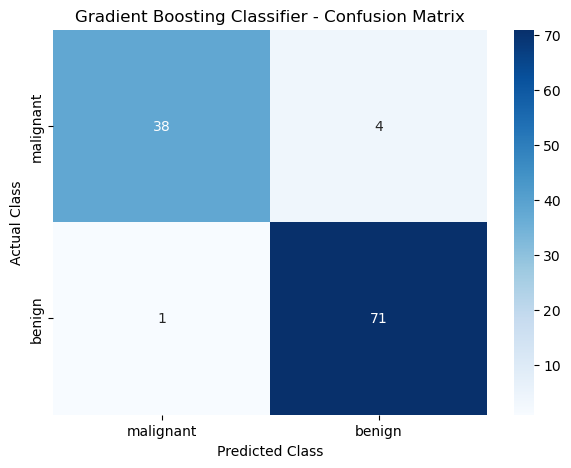

In [56]:
# Confusion matrix
gbc_cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(gbc_cm,annot=True,fmt='d',cmap='Blues',xticklabels=cancer.target_names,yticklabels=cancer.target_names)

plt.title('Gradient Boosting Classifier - Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.show()

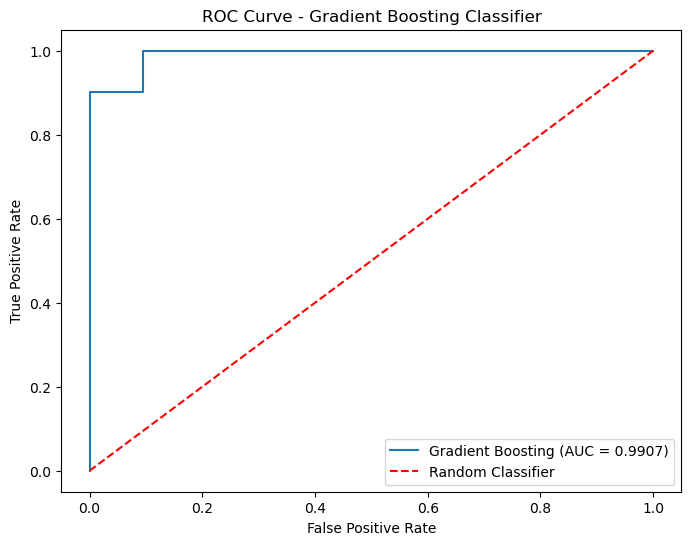

In [57]:
# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

plt.figure(figsize=(8, 6))

plt.plot(fpr,tpr,label=f'Gradient Boosting (AUC = {gbc_roc_auc:.4f})')

plt.plot([0, 1], [0, 1], linestyle='--', color='red', label='Random Classifier')

plt.title('ROC Curve - Gradient Boosting Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

In [58]:
# training vs testig performance

# Generate training predictions
y_train_pred = gbc.predict(X_train)

# Calculate accuracy scores
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Training Accuracy: {train_accuracy:.6f}")
print(f"Testing Accuracy: {test_accuracy:.6f}")

Training Accuracy: 1.000000
Testing Accuracy: 0.956140


,Feature,Importance
20,worst radius,0.435500
22,worst perimeter,0.271483
27,worst concave points,0.106549
21,worst texture,0.052638
7,mean concave points,0.030458
11,texture error,0.026927
23,worst area,0.022313
26,worst concavity,0.010819
24,worst smoothness,0.010706
13,area error,0.005348


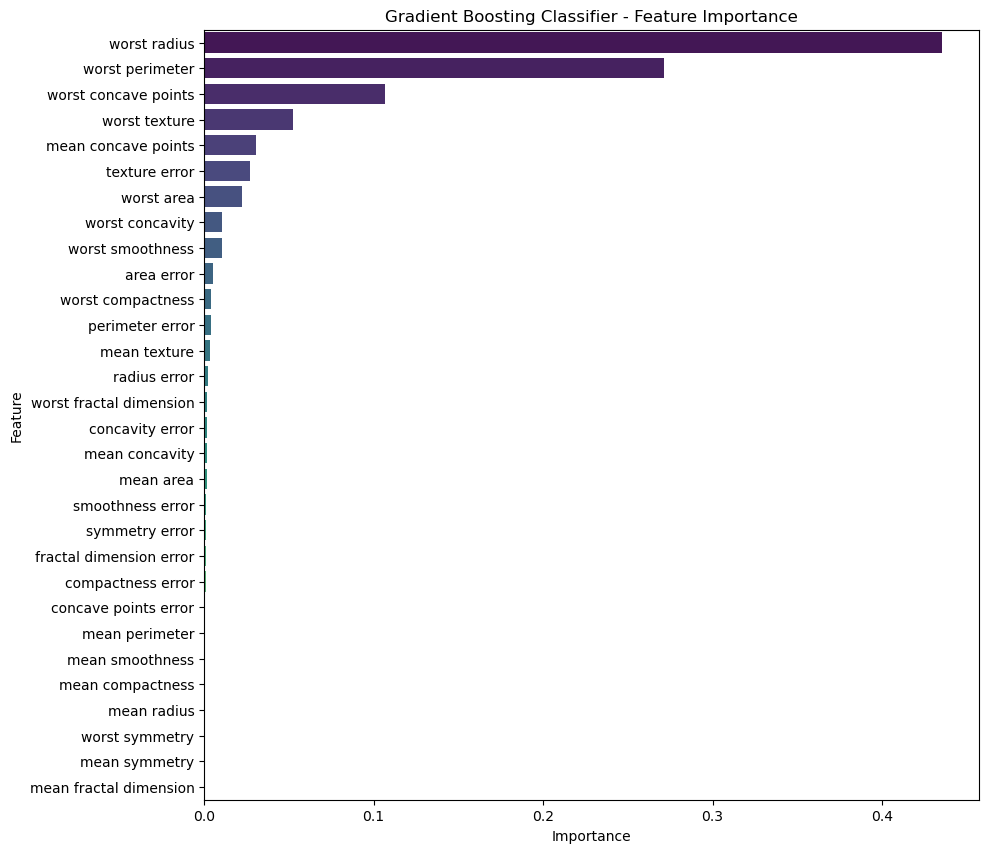

In [59]:
# feature importance

# Extract feature importance
gbc_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': gbc.feature_importances_
})

# Sort feature importance
gbc_importance = gbc_importance.sort_values(
    by='Importance',
    ascending=False
)

display(gbc_importance)

# Visualize feature importance
plt.figure(figsize=(10, 10))

sns.barplot(data=gbc_importance,x='Importance',y='Feature',hue='Feature',palette='viridis',legend=False)

plt.title('Gradient Boosting Classifier - Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')

plt.show()

In [60]:
# Hyperparameter Tuning
# Define hyperparameter grid
gbc_param_grid = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.05, 0.1],
    'max_depth': [2, 3],
    'min_samples_split': [2, 5],
    'subsample': [0.8, 1.0]
}

# Initialize GridSearchCV
gbc_grid = GridSearchCV(estimator=GradientBoostingClassifier(random_state=42),param_grid=gbc_param_grid,cv=3,scoring='f1',n_jobs=-1,verbose=1)

# Fit GridSearchCV
gbc_grid.fit(X_train, y_train)

Fitting 3 folds for each of 48 candidates, totalling 144 fits


,estimator,GradientBoost...ndom_state=42)
,param_grid,"{'learning_rate': [0.05, 0.1], 'max_depth': [2, 3], 'min_samples_split': [2, 5], 'n_estimators': [50, 100, ...], ...}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,3
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,loss,'log_loss'


In [61]:
# Display best parameters
print("Best Parameters:")
print(gbc_grid.best_params_)

# Best cross-validation F1 score
print("\nBest CV F1 Score:", gbc_grid.best_score_)

Best Parameters:
{'learning_rate': 0.1, 'max_depth': 2, 'min_samples_split': 5, 'n_estimators': 150, 'subsample': 0.8}

Best CV F1 Score: 0.9757256388835337


In [62]:
# Retrieve best estimator
gbc_tuned = gbc_grid.best_estimator_

# Generate predictions
y_pred_tuned = gbc_tuned.predict(X_test)

# Generate predicted probabilities
y_pred_proba_tuned = gbc_tuned.predict_proba(X_test)[:, 1]

In [63]:
# Evaluate tuned model
tuned_accuracy = accuracy_score(y_test, y_pred_tuned)
tuned_precision = precision_score(y_test, y_pred_tuned)
tuned_recall = recall_score(y_test, y_pred_tuned)
tuned_f1 = f1_score(y_test, y_pred_tuned)

tuned_roc_auc = roc_auc_score(y_test, y_pred_proba_tuned)

# Display result
print(f"Accuracy:  {tuned_accuracy:.6f}")
print(f"Precision: {tuned_precision:.6f}")
print(f"Recall:    {tuned_recall:.6f}")
print(f"F1 Score:  {tuned_f1:.6f}")
print(f"ROC-AUC:   {tuned_roc_auc:.6f}")


Accuracy:  0.947368
Precision: 0.945946
Recall:    0.972222
F1 Score:  0.958904
ROC-AUC:   0.992725


In [64]:
# Compare classification performance
gbc_comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC'],
    'Original Model': [
        gbc_accuracy,
        gbc_precision,
        gbc_recall,
        gbc_f1,
        gbc_roc_auc
    ],
    'Tuned Model': [
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1,
        tuned_roc_auc
    ]
})

display(gbc_comparison)

,Metric,Original Model,Tuned Model
0,Accuracy,0.956140,0.947368
1,Precision,0.946667,0.945946
2,Recall,0.986111,0.972222
3,F1 Score,0.965986,0.958904
4,ROC-AUC,0.990741,0.992725


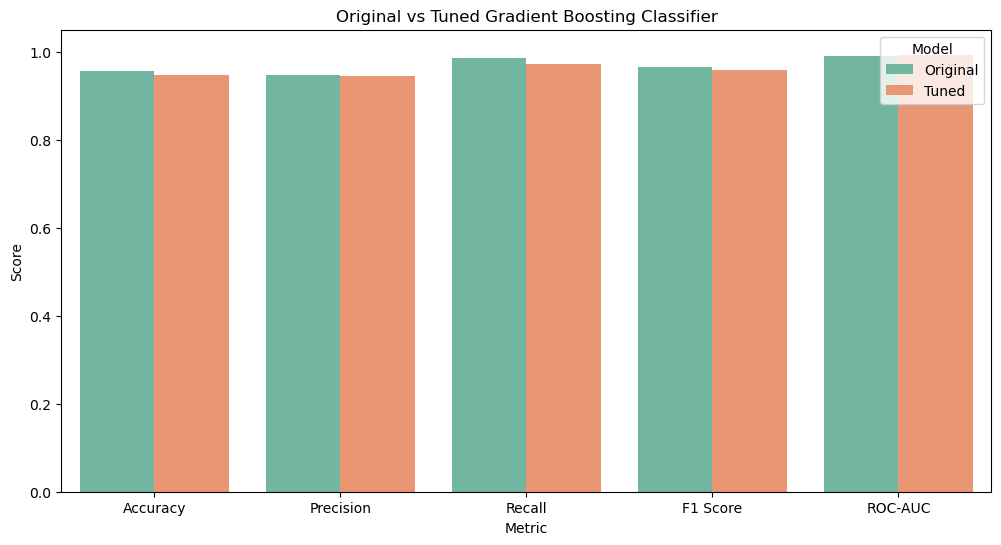

In [65]:
comparison_data = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC'] * 2,
    'Score': [
        gbc_accuracy,
        gbc_precision,
        gbc_recall,
        gbc_f1,
        gbc_roc_auc,
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1,
        tuned_roc_auc
    ],
    'Model': ['Original'] * 5 + ['Tuned'] * 5
})

plt.figure(figsize=(12, 6))

sns.barplot(data=comparison_data,x='Metric',y='Score',hue='Model',palette='Set2')

plt.title('Original vs Tuned Gradient Boosting Classifier')
plt.ylim(0, 1.05)
plt.show()

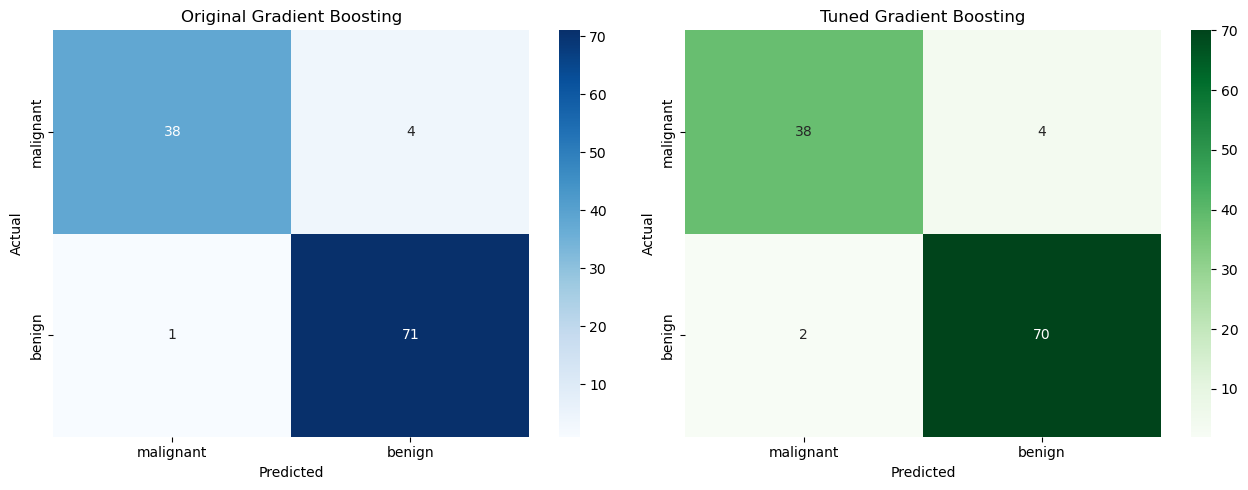

In [66]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Original model
sns.heatmap(confusion_matrix(y_test, y_pred),annot=True,fmt='d',cmap='Blues',xticklabels=cancer.target_names,yticklabels=cancer.target_names,ax=axes[0])

axes[0].set_title('Original Gradient Boosting')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# Tuned model
sns.heatmap(confusion_matrix(y_test, y_pred_tuned),annot=True,fmt='d',cmap='Greens',xticklabels=cancer.target_names,yticklabels=cancer.target_names,ax=axes[1])

axes[1].set_title('Tuned Gradient Boosting')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

# Overall Conclusion

Gradient Boosting was implemented for both regression and classification tasks.

For regression, the California Housing dataset was used to predict median house values. The baseline and tuned models were evaluated using MAE, MSE, RMSE, and R².

For classification, the Breast Cancer Wisconsin dataset was used to distinguish between malignant and benign tumours. The models were evaluated using accuracy, precision, recall, F1-score, ROC-AUC, and confusion matrices.

GridSearchCV was used in both tasks to identify suitable hyperparameter combinations and compare tuned models against their baselines.

The experiments demonstrated the ability of Gradient Boosting to build strong predictive models by combining weak learners sequentially.

The project also explored feature importance, residual analysis, model evaluation, and hyperparameter optimization.

Gradient Boosting is a powerful ensemble learning technique, although its performance depends on appropriate parameter selection and careful evaluation.
